
# COU 07506 – DIGITAL SIGNAL PROCESSING

## WEEK 1 – LAB 0
### Setting Up the DSP Laboratory

**Name:** Amani Bashiru Ali

**Registration Number:** 240242472751

**Date:** 24 November 2026

**Group:** 25


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)


In [2]:

# Generate the sample index
n = np.arange(-5, 11)

# 1. Unit Impulse
delta = (n == 0).astype(float)

# 2. Unit Step
step = (n >= 0).astype(float)

# 3. Unit Ramp
ramp = n * step

# 4. Real Exponential
expo = 0.8**n * step


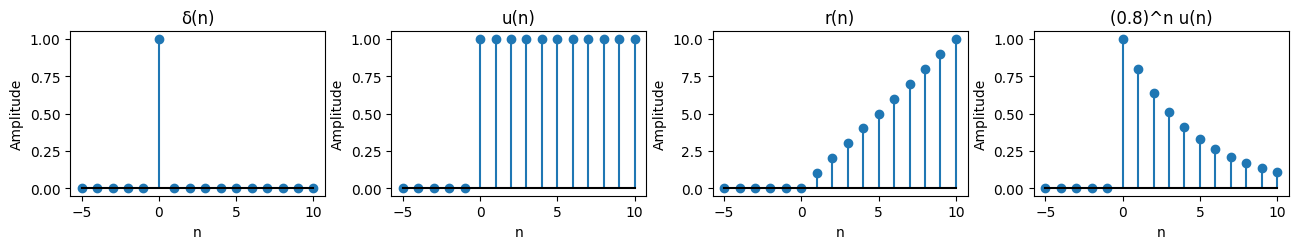

In [3]:

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()


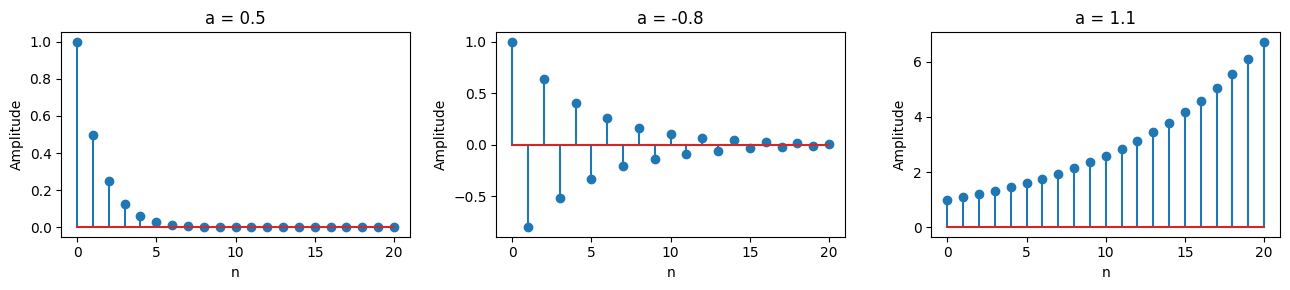

In [4]:

# Create sample index
n = np.arange(0, 21)

# Generate three exponential signals
a1 = 0.5**n
a2 = (-0.8)**n
a3 = 1.1**n

# Plot the three signals
fig, axes = plt.subplots(1, 3, figsize=(13, 3))

axes[0].stem(n, a1)
axes[0].set_title("a = 0.5")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")

axes[1].stem(n, a2)
axes[1].set_title("a = -0.8")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")

axes[2].stem(n, a3)
axes[2].set_title("a = 1.1")
axes[2].set_xlabel("n")
axes[2].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()


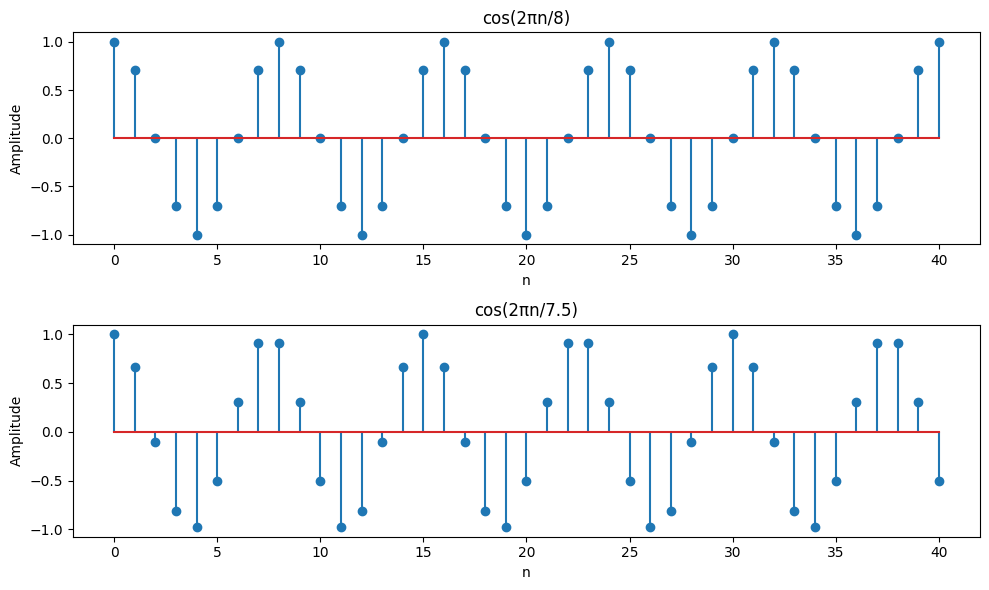

In [5]:

# Generate sample index
n = np.arange(0, 41)

# Generate cosine signals
x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

# Plot both signals
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1)
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")

axes[1].stem(n, x2)
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()


fs = 44100 Hz, duration = 4.85 s, samples = 214016


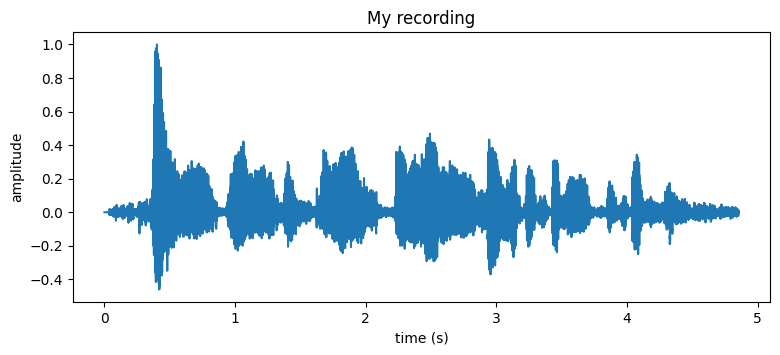

In [6]:

import os

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x / np.max(np.abs(x))

else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs

print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()


In [7]:

from IPython.display import Audio

Audio(x, rate=fs)



## Pre-Lab Question

Three devices that use Digital Signal Processing (DSP) are:

1. Smartphone – Processes voice and audio signals during calls and recordings.
2. Laptop – Processes audio signals during playback and recording.
3. Digital headphones – Process sound signals to improve audio output.



### Analysis Question 1

**Question:** What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?

**Answer:**

The sampling rate of my phone's recording is 44,100 Hz. This means that 44,100 audio samples are recorded every second.

One minute contains 60 seconds.

Number of samples = Sampling rate × Time

= 44,100 × 60

= 2,646,000 samples.

Therefore, 2,646,000 numbers are needed to store one minute of mono audio.


### Analysis Question 2

**Question:** Why is a stem plot more appropriate than a continuous line for x(n)?

**Answer:**

A discrete-time signal x(n) is defined only at integer values of n. There are no values between the samples, for example x(2.5) does not exist.

A stem plot draws each sample as a separate vertical line at its own index n, so it shows correctly that the signal exists only at distinct points.

A continuous line would join the samples and wrongly suggest that the signal has values between them, which is not true for a discrete-time signal. Therefore, a stem plot represents x(n) more accurately.

### Analysis Question 3

**Question:** For a = 1.1 the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?

**Answer:**

It would violate the property of **stability** (BIBO stability: bounded input gives bounded output).

An LTI system is BIBO stable only if its impulse response is absolutely summable:

sum of |h(n)| for all n < infinity.

For h(n) = (1.1)^n u(n), the values grow without limit (1, 1.1, 1.21, ...), so the sum of |h(n)| is infinite.

Therefore a bounded input can produce an unbounded output, and the system is unstable.

### AI-use statement

AI tools used: Claude (AI chat assistant)

Used for: explaining the tasks and analysis questions step by step, and helping me understand the theory (sampling rate, stem plots, BIBO stability).

How I verified the output: I ran every code cell myself and checked the printed sampling rate, duration and number of samples against my own calculation (fs x T). I compared the plots with the expected results in the manual.

I confirm that I understand and can explain all submitted code.